# easyspec tutorial: color images of a nebula

From the raw images of the **Crab Nebula** (M1) to a color image, and to a second color image
where the stars were removed, leaving only the nebula.

**The data** are raw frames of FORS1, the imager and spectrograph of the VLT (UT1, Paranal), taken on the night of 2003-12-17/18 in three Bessel filters, B, V and R: two jittered exposures of the
centre of the nebula per filter (30 s in B, 20 s in V and R), five bias frames and three twilight (sky) flats per filter.

```
eso_Crab_photometry/
    bias/                           bias frames
    flats_B/, flats_V/, flats_R/    twilight flats
    Crab_B/, Crab_V/, Crab_R/       the nebula, two exposures per filter
```

In [7]:
from pathlib import Path
import numpy as np
from easyspec.cleaning import cleaning

data = Path("eso_Crab_photometry")
out = Path("imaging_output")
out.mkdir(exist_ok=True)

## 1. Reduction with `cleaning`

Three things are specific to FORS1, and all come from the header (`fits.getheader()` of any raw frame):

- **Trim**: the frames have 2080 × 2048 pixels, of which 2048 × 2048 are illuminated.
- **Gain**: in this mode the CCD is read through four outputs (one per quadrant), each with its own gain (`ESO DET OUT1 CONAD` to
  `ESO DET OUT4 CONAD`: 1.46, 1.59, 1.78 and 1.65 electrons per ADU) and its own bias level. The bias level is removed by the master
  bias, and the different gains by the flat field: a quadrant with a larger gain gives fewer ADU for the same light in the flats as in the
  images, so the division by the normalized flat puts all quadrants on the same scale. `gain_correct()` then needs a single number: we
  use the gain of the first output, which only sets the conversion to electrons (and the noise model) to within ~10%.
- **Read noise**: `ESO DET OUT1 RON` (≈ 5.2 electrons; 5.2 to 5.6 in the other outputs).

One `cleaning` session per filter: the two exposures of each filter are **aligned** (`align()` finds the shift of ~100 pixels between them from the
stars) and **combined** with `master()`. With `crop=False`, the aligned images keep their full size and the pixels outside the
overlapping region become NaN: in this way the masters of all filters have the same size, which `generate_colored_image()` needs.

In [2]:
def reduce_filter(fors_filter, plot=False):
    c = cleaning()

    bias_folder = data/"bias"
    flat_folder = data/f"flats_{fors_filter}"
    nebula_folder = data/f"Crab_{fors_filter}"
    raw = c.data_paths(bias=str(bias_folder), flats=str(flat_folder), targets=str(nebula_folder))

    # prescan columns on both sides (16 + 1 pixels) and the last row
    trimmed = c.trim(raw, x1=17, x2=2063, y1=0, y2=2047)

    master_bias = c.master("bias", trimmed, plot=False)
    debiased = c.debias(trimmed, master_bias)

    master_flat = c.master("flat", debiased, plot=False)
    norm_flat = c.norm_master_flat(master_flat, method="imaging", plots=False)   # "imaging": keeps vignetting and quadrant gains
    flattened = c.flatten(debiased, norm_flat)

    electrons = c.gain_correct(flattened, gain_header_entry="ESO DET OUT1 CONAD", verbose=False)
    cleaned = c.remove_cosmic_rays(electrons, readnoise_header_entry="ESO DET OUT1 RON", verbose=False)
    variance, mask = c.compute_variance(cleaned, readnoise_header_entry="ESO DET OUT1 RON", verbose=False)

    aligned, aligned_variance, aligned_mask = c.align(cleaned, Type="all", crop=False, fill_value=np.nan,
                                                      variance=variance, mask=mask)
    c.master("target", aligned, method="mean", exposure_header_entry="EXPTIME",
             airmass_header_entry="ESO TEL AIRM START", variance=aligned_variance, mask=aligned_mask, plot=plot)

    # master() writes master_target_<folder>.fits in the current directory: we move it to the output folder
    (out/f"Crab_{fors_filter}").mkdir(exist_ok=True)
    Path(f"master_target_Crab_{fors_filter}.fits").replace(out/f"Crab_{fors_filter}"/f"master_target_Crab_{fors_filter}.fits")

Normalized master flat: 2047/2047 illuminated rows; median = 1.0255; robust scatter = 0.0985; 57 pixels set to 1 (low signal).
461 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.38%, from 0.29% to 0.75% depending on the column.
Group 'Crab_B' - reference image: FORS1.2003-12-18T05:50:20.393.fits
  FORS1.2003-12-18T05:51:49.637.fits: method = stars, rotation = -0.008 deg, center shift (dx, dy) = (+100.51, +100.42) px, matched stars = 35, rms = 0.842 px


/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master target have different exposure times (29.9973 to 29.9975). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


Normalized master flat: 2047/2047 illuminated rows; median = 1.0136; robust scatter = 0.1031; 31 pixels set to 1 (low signal).
446 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.27%, from 0.26% to 0.28% depending on the column.
Group 'Crab_V' - reference image: FORS1.2003-12-18T05:55:05.423.fits
  FORS1.2003-12-18T05:56:22.855.fits: method = stars, rotation = -0.002 deg, center shift (dx, dy) = (-101.34, -100.19) px, matched stars = 44, rms = 0.816 px


/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master target have different exposure times (19.9971 to 19.9972). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


Normalized master flat: 2047/2047 illuminated rows; median = 0.9943; robust scatter = 0.0965; 27 pixels set to 1 (low signal).
473 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.28%, from 0.27% to 0.28% depending on the column.
Group 'Crab_R' - reference image: FORS1.2003-12-18T05:59:09.013.fits
  FORS1.2003-12-18T06:00:30.505.fits: method = stars, rotation = -0.003 deg, center shift (dx, dy) = (+100.39, +100.02) px, matched stars = 46, rms = 0.780 px


/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:535: RuntimeWarning: invalid value encountered in subtract
  independent = sum(np.clip(np.asarray(variance[frame], dtype=float) - c, 0, None)
/home/raniere/Documentos/easyspec/testes/Claude/easyspec/cleaning/cleaning.py:332: UserWarning: The frames combined into the master target have different exposure times (19.9981 to 19.9995). Consider normalizing them by their exposure times before combining.
  warnings.warn(f"The frames combined into the master {Type} have different exposure times "


In [ ]:
for fors_filter in ["B", "V", "R"]: 
    reduce_filter(fors_filter)

## 2. The color image

`generate_colored_image()` takes one image per filter and one color per image (usual choice: blue for the shortest wavelength, red for
the longest), aligns the images to each other (again from the stars) and combines them, each band painted with its color.

The first call does the slow steps, done only once:

- **alignment** of the bands onto a reference image (`reference`, the first one by default), from the stars (`alignment_method`,
  `fwhm`) with a bilinear interpolation (`interpolation_order=1`: higher orders are sharper but ring around saturated stars);
- `remove_saturated_pixels=True`: removes the bleeding trails of the saturated stars (the short vertical lines where the charge
  overflows along the columns of the CCD). Cosmetic only;
- `saturation_level`: there is no saturation keyword in the header, so we give it. The converter saturates at 65535 ADU, i.e.
  ≈ 65300 × 1.46 ≈ 95000 electrons after the bias, which the flat field changes by ±12% from quadrant to quadrant: 80000 electrons is
  safely below all of them.

With `plot_diagnostic=True`, a first plot shows all the aligned images and the box that is kept.

Exposure times: Crab_B/master_target_Crab_B.fits = 29.9974 s, Crab_V/master_target_Crab_V.fits = 19.9971 s, Crab_R/master_target_Crab_R.fits = 19.9988 s
Group 'colored image' - reference image: master_target_Crab_B.fits
  master_target_Crab_V.fits: method = stars, rotation = +0.005 deg, center shift (dx, dy) = (+0.29, -0.05) px, matched stars = 31, rms = 0.735 px
  master_target_Crab_R.fits: method = stars, rotation = -0.005 deg, center shift (dx, dy) = (-0.08, +0.19) px, matched stars = 37, rms = 0.521 px
Region with data in all 3 bands: x = 1-2045, y = 1-2046 (2044 x 2045 pixels)


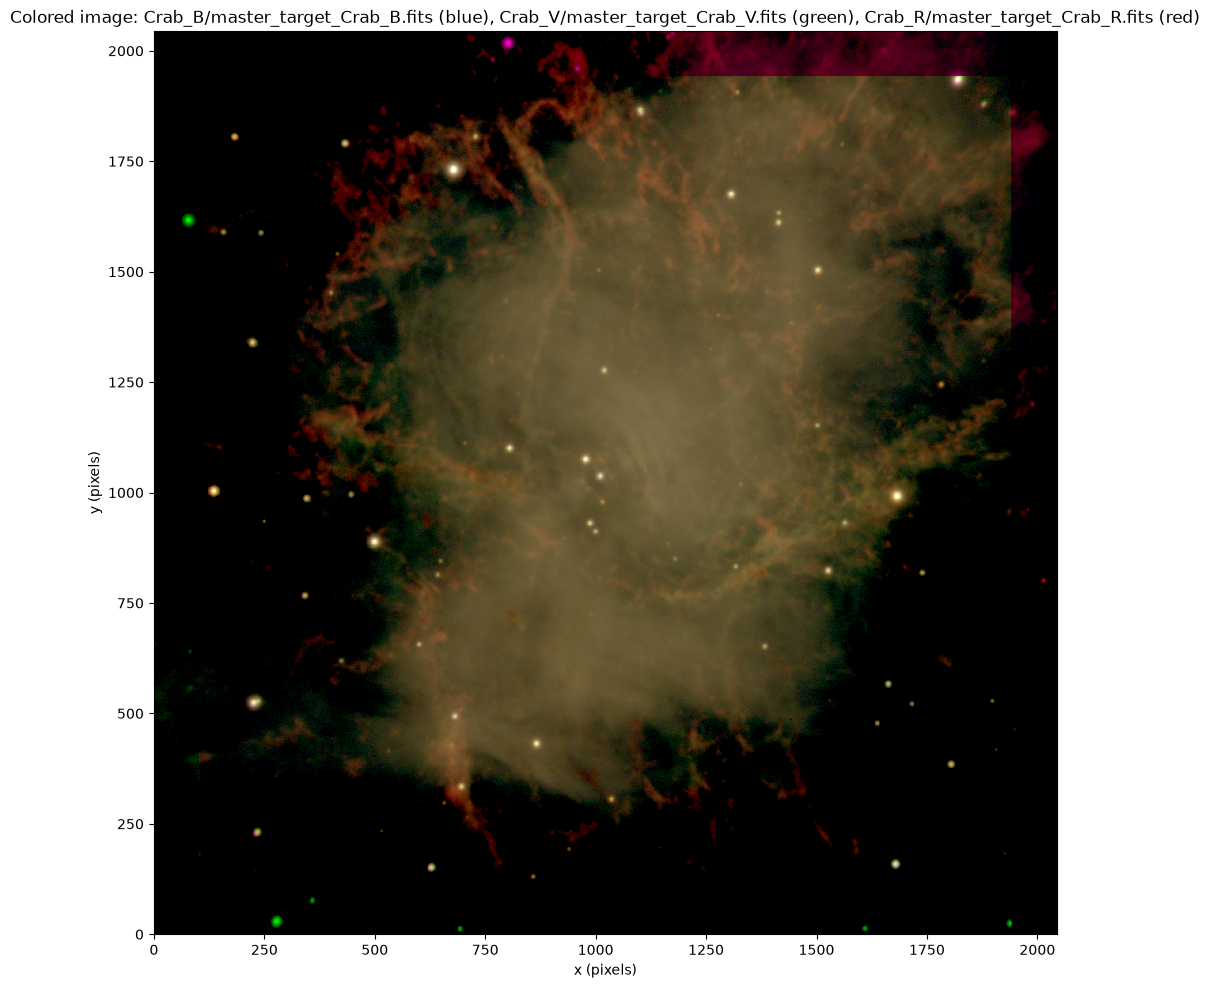

In [8]:
c = cleaning()

nebula_images = [out/"Crab_B"/"master_target_Crab_B.fits",
                 out/"Crab_V"/"master_target_Crab_V.fits",
                 out/"Crab_R"/"master_target_Crab_R.fits"]
colors = ["blue", "green", "red"]     # B, V, R
saturation_level = 80000              # electrons

colored = c.generate_colored_image(nebula_images, colors,
                                   reference=0,                       # align onto the first image (B)
                                   alignment_method="auto",           # "auto", "stars" or "correlation"
                                   interpolation_order=1,             # bilinear (default)
                                   fwhm=4.0,                          # approximate FWHM of the stars (pixels), for the alignment
                                   remove_saturated_pixels=False,      # remove the bleeding trails (cosmetic)
                                   saturation_level=saturation_level,
                                   plot_diagnostic=False)              # aligned images and the box that is kept

By default (`band_scaling="exposure"`) the images are divided by their exposure times and share the same white point, so the colors
show the real ratios of the count rates. The result is faithful, but not very colorful: the synchrotron light of the nebula has a smooth
spectrum, and dominates in all three filters.

### Making it beautiful

Now the image can be changed at will. The slow steps (alignment, removal of the trails) are not repeated when the result of the previous
call (`colored`) is given instead of the files, so each new version takes a second or two. The main options:

- `colors`: one color per band. Here the filaments shine in emission lines: [O III] (green) falls in V, and Hα and [N II] (red) in R,
  which makes the filaments green and red against the blue-white synchrotron glow;
- `band_scaling="separate"`: each band normalized on its own (as with independent scales in DS9): stronger colors, no longer
  proportional to the fluxes;
- `white_percentile`: the percentile that becomes white (lower: brighter image, more saturated stars);
- `black_level`: the black point, in units of the noise of the sky (1 or 2 hide the noise of the sky; negative values make it grey);
- `band_weights`: multiplies each band (the main control of the color balance);
- `smoothing_sigma`: Gaussian smoothing in pixels (less noise in faint diffuse light, less resolution);
- `stretch` (`"log"`, `"asinh"` or `"linear"`) and `stretch_strength`: larger values show fainter features;
- `color_mode`: `"channels"` (as DS9: the cores of bright stars turn white) or `"preserve"` (the colors are kept up to the center);
- `gamma`, `color_saturation`, `contrast` and `brightness`: the usual photo-editing controls;
- `region=(x1, x2, y1, y2)`: zoom on a part of the image; `flip_x`/`flip_y`: mirror it (here north is already up and east left);
- `title`, `figure_size`, `show_axes` and `output_file`: the plot and the saved file (png, or fits with the WCS).

The settings below reproduce the look of DS9 with the three bands in log scale: each channel scaled on its own between its minimum and
its maximum (`white_percentile=100`; `black_level` ≈ −1.9 is the minimum, −1 gives a slightly darker sky), with the log stretch of DS9.
The `region` cuts the edges of the field where only some bands have data (the jitter between the exposures: about 100 pixels on each
side).

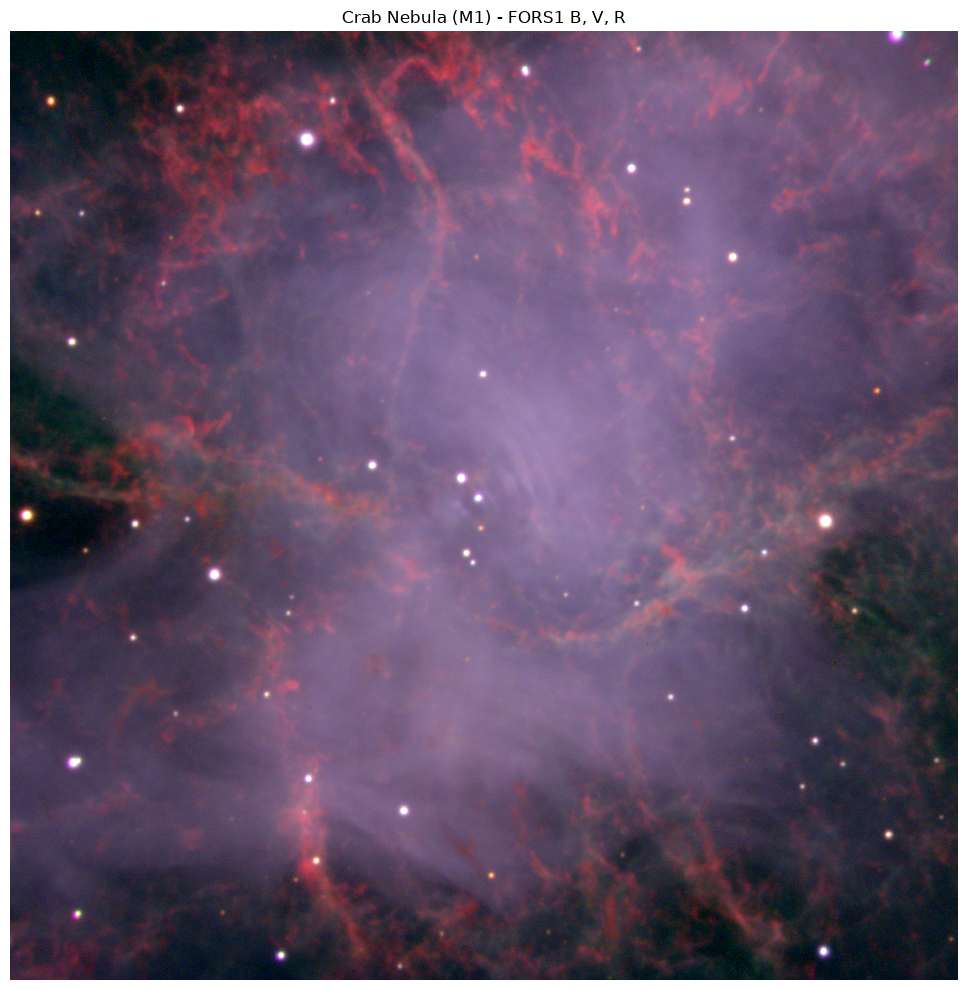

Colored image saved in imaging_output/crab_color.png


In [4]:
colored = c.generate_colored_image(colored, colors,           # previous result: no new alignment, a few seconds
                                   band_scaling="separate",        # each channel scaled on its own, as in DS9
                                   white_percentile=100,           # white = maximum of each band (DS9 "minmax")
                                   black_level=-1,                 # -1.9 = minimum of each band (DS9 "minmax"); -1: darker sky
                                   band_weights=[1, 1, 1],         # default None (all 1)
                                   smoothing_sigma=0,              # default 0 (no smoothing)
                                   stretch="log",                  # DS9 log scale
                                   stretch_strength=1000,          # DS9 log exponent
                                   color_mode="channels",          # channels stretched separately, as in DS9
                                   gamma=1.0,                      # default 1
                                   color_saturation=1.8,           # default 1 (> 1: more vivid colors)
                                   contrast=1.0,                   # default 1
                                   brightness=2.0,                 # default 1
                                   region=(104, 1939, 104, 1941),  # (x1, x2, y1, y2): only where all bands have data
                                   flip_x=False, flip_y=False,     # default False
                                   title="Crab Nebula (M1) - FORS1 B, V, R",
                                   figure_size=(10, 10),
                                   show_axes=False,
                                   output_file=out/"crab_color.png")

The blue-white glow is the synchrotron emission of electrons accelerated by the pulsar (one of the two stars at the centre, the south-west
one of the pair), spiraling in the magnetic field of the nebula; the red and green filaments are the gas ejected by the supernova,
ionized by that light. The filaments are green where [O III] dominates and red where Hα and [N II] dominate.

## 3. The nebula without the stars

With `remove_stars=True`, every image is fitted with an empirical PSF (`easyspec.photometry.psf_photometry()`, the same function used
for PSF photometry), and the models of the stars are subtracted, which keeps the light of the nebula underneath. The cores of saturated
and very bright stars, where the subtraction cannot be trusted, are filled with the light around them (the same pixels in all bands, so
that the colors stay consistent). The extended halos of the brightest stars are not removed.

Only the stars found in **all** bands are removed. In a nebula with filaments, `psf_photometry()` also finds the small knots of the
filaments and fits them as if they were stars: in R, more than 2000 "stars" are found, most of them knots that shine in Hα. These knots
are not found in all bands at the same position, so they stay in the image, while the real stars, seen in all bands, are removed.

The `saturation_level` must be given here too: the cores of the saturated stars are not well subtracted and are filled with the light
around them. This step takes some minutes (the PSF fit of the three images). The edges where only some bands have data are cut
automatically, so `region` is not needed.

Crab_B/master_target_Crab_B.fits: saturation level 80000; 0 pixels of saturation trails replaced
Crab_V/master_target_Crab_V.fits: saturation level 80000; 0 pixels of saturation trails replaced
Crab_R/master_target_Crab_R.fits: saturation level 80000; 0 pixels of saturation trails replaced
Group 'colored image' - reference image: master_target_Crab_B.fits
  master_target_Crab_V.fits: method = stars, rotation = +0.005 deg, center shift (dx, dy) = (+0.29, -0.05) px, matched stars = 31, rms = 0.735 px
  master_target_Crab_R.fits: method = stars, rotation = -0.005 deg, center shift (dx, dy) = (-0.08, +0.19) px, matched stars = 37, rms = 0.521 px
master_target_Crab_B.fits: FWHM = 7.80 px, scatter 0.16 px from 40 stars; sky = 91.1 e-, RMS = 7.54 e-; 141 sources above 5.0 sigma
master_target_Crab_B.fits: empirical PSF from 30 stars (stamp 57 px, oversampling 2)
   iteration 1: 141 stars fitted (grouping distance 2.00 FWHM), 47 new stars found in the residual image
   iteration 2: 182 stars fi

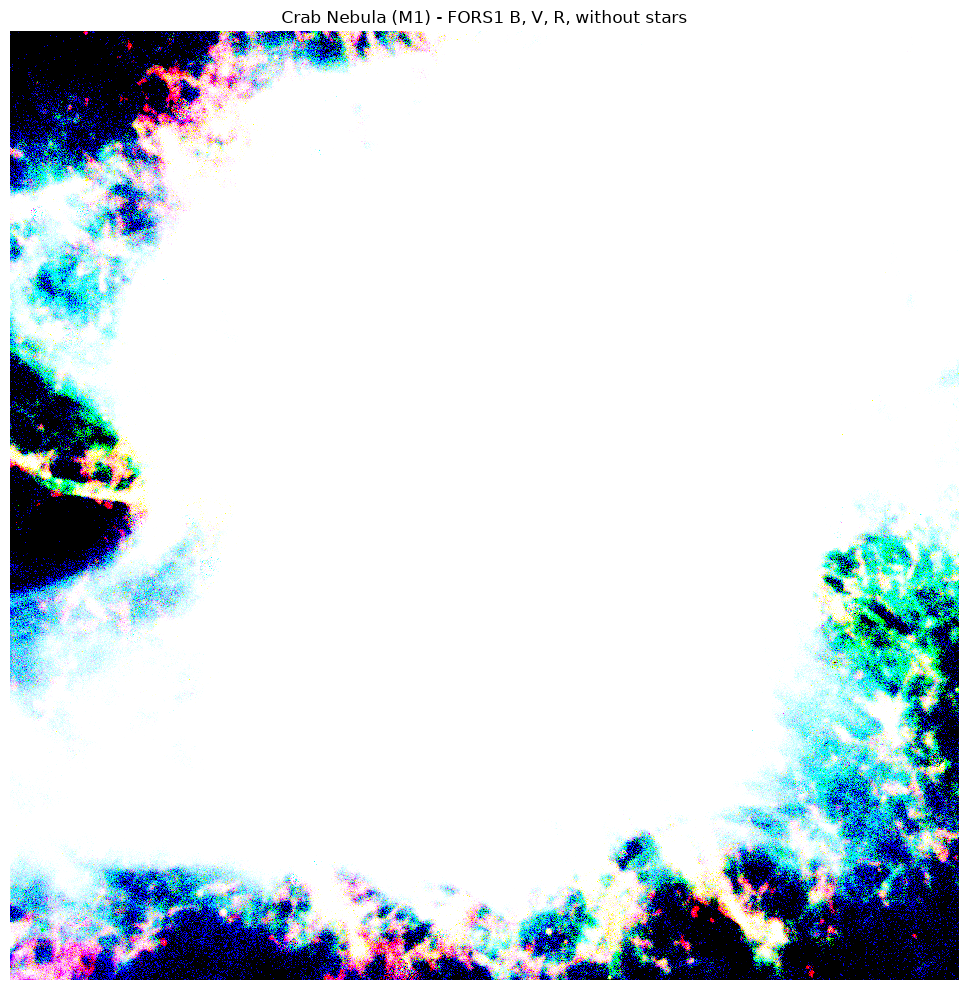

In [5]:
nebula_only = c.generate_colored_image(nebula_images, colors,
                                       remove_stars=True,                  # subtract the stars found in all bands with their PSF
                                       remove_saturated_pixels=True,       # remove the bleeding trails (cosmetic)
                                       saturation_level=saturation_level,  # needed: the saturated cores are filled, not subtracted
                                       band_scaling="separate",            # each channel scaled on its own, as in DS9
                                       white_percentile=100,               # white = maximum of each band (DS9 "minmax")
                                       black_level=-1,                     # -1.9 = minimum of each band (DS9 "minmax"); -1: darker sky
                                       band_weights=[1, 1, 1],             # default None (all 1)
                                       smoothing_sigma=0,                  # default 0 (no smoothing)
                                       stretch="log",                      # DS9 log scale
                                       stretch_strength=1000,              # DS9 log exponent
                                       color_mode="channels",              # channels stretched separately, as in DS9
                                       gamma=1.0,                          # default 1
                                       color_saturation=1.8,               # default 1 (> 1: more vivid colors)
                                       contrast=1.0,                       # default 1
                                       brightness=2.0,                     # default 1
                                       region=None,                        # the edges are already cut
                                       flip_x=False, flip_y=False,         # default False
                                       title="Crab Nebula (M1) - FORS1 B, V, R, without stars",
                                       figure_size=(10, 10),
                                       show_axes=False)

The stars are gone, but the image is now much too bright. The reason is the white point: `white_percentile=100` puts the white at the
maximum of each band, which was the core of a bright star and is now the brightest part of the nebula, about a hundred times fainter.
The whole nebula is then close to the white point, and the log stretch, which strongly brightens the faint levels, pushes it to white.

As before, the result can be changed without repeating the slow steps. A linear stretch keeps the brightness proportional to the flux,
which suits an image whose only content is the nebula. The small smooth patches near the centre are the places of the brightest stars
(including the pulsar), filled with the light around them.

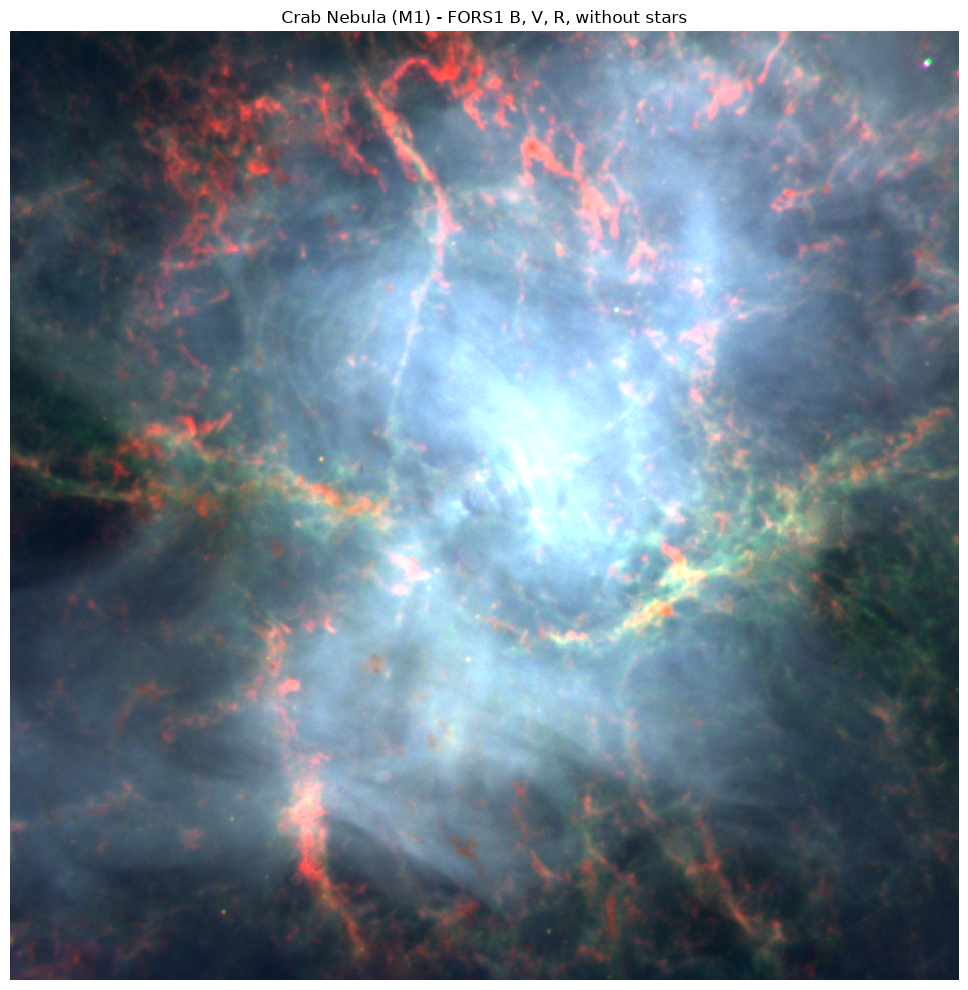

Colored image saved in imaging_output/crab_color_no_stars.png


In [6]:
final_image = c.generate_colored_image(nebula_only, colors,             # previous result: no new PSF fits, a few seconds
                                       band_scaling="separate",          # each channel scaled on its own
                                       white_percentile=100,             # white = maximum of each band
                                       black_level=-1.8,                 # close to the minimum of each band
                                       band_weights=[0.8, 1, 1],         # a little less blue
                                       smoothing_sigma=1,                # light smoothing (pixels): less noise
                                       stretch="linear",                 # brightness proportional to the flux
                                       color_mode="channels",            # default "channels"
                                       gamma=1.0,                        # default 1
                                       color_saturation=1.8,             # default 1 (> 1: more vivid colors)
                                       contrast=1.0,                     # default 1
                                       brightness=2.0,                   # default 1
                                       region=None,                      # default None (whole image)
                                       flip_x=False, flip_y=False,       # default False
                                       title="Crab Nebula (M1) - FORS1 B, V, R, without stars",
                                       figure_size=(10, 10),
                                       show_axes=False,
                                       output_file=out/"crab_color_no_stars.png")